### IPD440 - APRENDIZAJE DE MAQUINAS
# Clase 13: Attention
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Sequence to sequence learning

<div align="center">
    <img src="img/seq2seq.png" alt="" width="80%" align="center" />
</div>

## Problema con seq2seq learning

La representación intermedia $\mathbf{z}$ no puede codificar información de todos los instantes de tiempo en la secuencia de entrada. Esto se conoce comúnmente como el problema del cuello de botella.

En teoría, las matemáticas indican que es posible capturar toda la información sobre la secuencia de entrada. Sin embargo, en la práctica, hasta dónde podemos ver en el pasado (la llamada ventana de referencia) es finita. Por lo tanto, las RNN tienden a olvidar información de los instantes de tiempo que están muy atrás.

<div align="center">
    <img src="img/scope-per-senquence-length.png" alt="" width="40%" align="center" />
</div>

### Problema del desvanecimiento de gradiente (Vanishing gradient problem)

<div align="center">
    <img src="img/memorization-rnns.png" alt="" width="80%" align="center" />
</div>

# Atención al rescate!

<div align="center">
    <img src="img/attention.png" alt="" width="30%" align="center" />
</div>

La idea central es que el vector de contexto $\mathbf{z}$ debería tener acceso a todas las partes de la secuencia de entrada en lugar de solo a la última. En otras palabras, necesitamos formar una conexión directa con cada instante de tiempo.


Esto es lo que ahora llamamos atención, que es simplemente una noción de memoria, obtenida al prestar atención a múltiples entradas a lo largo del tiempo.

## Atención implícita

Las redes neuronales muy profundas ya aprenden una forma de atención implícita. Por ejemplo, las CNN se enfocan en ciertos píxeles para detectar objetos (Saliency Maps).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from keras import backend as K
from PIL import Image
import os
import re
import time
import pandas as pd
import unicodedata

In [2]:
import warnings
from cryptography.utils import CryptographyDeprecationWarning
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', category=CryptographyDeprecationWarning)
from skimage.transform import resize

In [3]:
from keras.applications.vgg16 import VGG16
vgg16_model = VGG16(weights='imagenet')

In [4]:
def activacion(model, img, layer="block5_conv3"):
    preprocess_img = keras.preprocessing.image.img_to_array(img)
    preprocess_img = np.expand_dims(preprocess_img, axis=0)
    preprocess_img = keras.applications.vgg16.preprocess_input(preprocess_img)    
    
    conv_layer = model.get_layer(layer)
    heatmap_model = keras.models.Model([model.inputs], [conv_layer.output, model.output])

    with tf.GradientTape() as gtape:
        conv_output, predictions = heatmap_model(preprocess_img)
        loss = predictions[:, np.argmax(predictions[0])]
        grads = gtape.gradient(loss, conv_output)
        pooled_grads = K.mean(grads, axis=(0, 1, 2))
    
    top_K = keras.applications.vgg16.decode_predictions(predictions.numpy(), top=1)[0]    

    heatmap = tf.reduce_mean(tf.multiply(pooled_grads, conv_output), axis=-1)
    heatmap = np.maximum(heatmap, 0)
    max_heat = np.max(heatmap)
    if max_heat == 0:
        max_heat = 1e-10
    heatmap /= max_heat
    hm=np.squeeze(heatmap)
    res = resize(hm, img.size)
    
    z = (res * 255).astype(np.uint8)
    pil_image=Image.fromarray(z).convert('RGB')
    
    im1 = img.convert('RGB')
    im = Image.blend(im1, pil_image, 0.8)
    pred = f"{top_K[0][1]} ({round(top_K[0][2] * 100,2)}%)"

    return im, pred

In [5]:
def activaciones(model,directory):
    images = []    
    for filename in os.listdir(directory):
        if re.search("\.(jpg)$", filename):
            images.append(directory+"/"+filename)
    
    fig, ax = plt.subplots(2, len(images), figsize=(20, 5))
    for i,x in enumerate(images):
        
        img = keras.preprocessing.image.load_img(x, target_size=(224, 224))
        ax[0,i].imshow(img)        
        ax[0,i].axis('off')
        
        maps, pred = activacion(model, img)
        
        ax[1,i].imshow(maps)
        ax[1,i].set_title(pred)
        ax[1,i].axis('off')

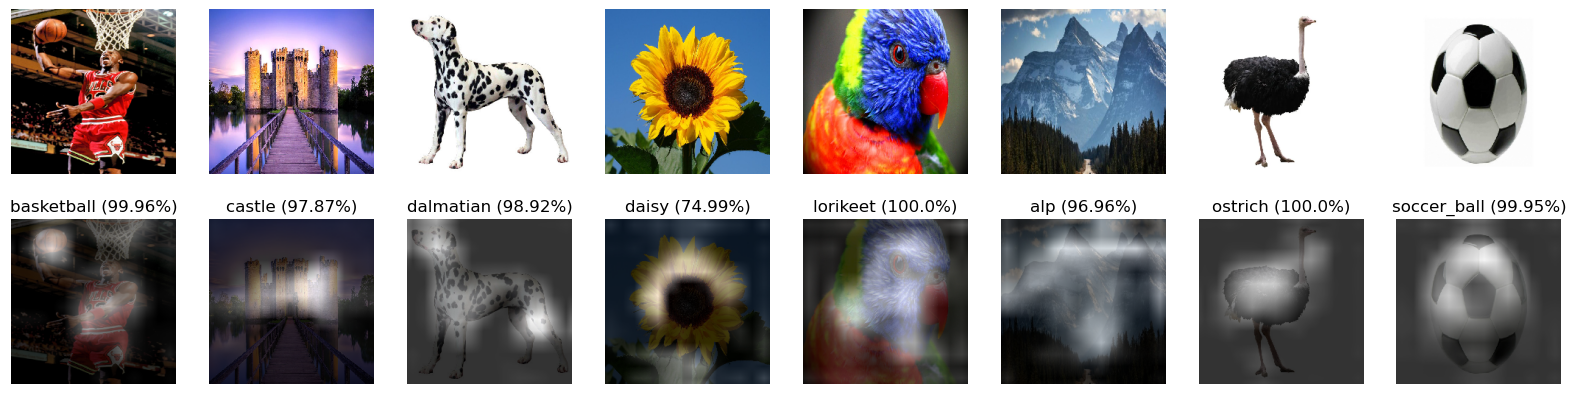

In [6]:
activaciones(vgg16_model, "test")

## Atención explícita

La red pondera su sensibilidad a la entrada en función de la memoria de entradas anteriores. 

<div align="center">
    <img src="img/sentence-example-attention.png" alt="" width="50%" align="center" />
</div>

# Modelo basado en la atención

<div align="center">
    <img src="img/attention_model.png" alt="" width="60%" align="center" />
</div>

Esto implementa un mecanismo de atención en el decodificador. El decodificador decide que partes de la sentencia de entrada debe prestar atención. Al permitir que el decodificador tenga un mecanismo de atención, liberamos al codificador de la carga de tener que codificar toda la información de la sentencia de entrada en un vector de longitud fija. Con este nuevo enfoque, la información se puede distribuir a lo largo de la secuencia de anotaciones, que el decodificador puede recuperar selectivamente en consecuencia.

## Mecanismo de atención

<div align="center">
    <img src="img/mechanism.png" alt="" width="60%" align="center" />
</div>

## Comparación de modelos seq2seq basados ​​​​en atención y sin atención

<div align="center">
    <img src="img/comparison.png" alt="" width="90%" align="center" />
</div>

# Self-attention

También podemos definir la atención de la misma secuencia, llamada autoatención. En lugar de buscar una asociación/alineación de secuencia de entrada-salida, ahora buscamos puntuaciones entre los elementos de la secuencia, como se muestra a continuación:

<div align="center">
    <img src="img/self-attention.png" alt="" width="30%" align="center" />
</div>

# Multi Head Attention

<div align="center">
    <img src="img/multi-head-attention.png" alt="" width="30%" align="center" />
</div>

# Neural Machine Translation

La traducción automática es la tarea de convertir automáticamente un texto de entrada en un idioma a un texto en otro idioma. 

Este es uno de los problemas más difíciles de la Inteligencia Artificial porque no existe la "mejor traducción" entre idiomas y muchas veces no hay palabras en el idioma destino para expresar el idioma origen. Esto se debe a la ambigüedad natural y la flexibilidad del lenguaje humano.

<div align="center">
    <img src="img/Translation.png" alt="" width="20%" align="center" />
</div>

Loading the dataset

In [7]:
# Load the dataset: sentence in english, sentence in spanish 
df=pd.read_csv('spa.txt', sep="\t", header=None, names=['input','target'], usecols=[0,1], nrows=20000)

In [8]:
sample = [4, 12279, 16853, 16196, 1454, 2952, 874, 10626]
df.iloc[sample,]

,input,target
4,Hi.,Hola.
12279,The man stood up.,El hombre se puso de pie.
16853,He closed his eyes.,Él cerró los ojos.
16196,Why didn't you go?,¿Por qué no fuiste?
1454,She's busy.,Ella está ocupada.
2952,I can't stay.,No me puedo quedar.
874,Stay home.,Quédate en casa.
10626,Explain it to me.,Acláramelo.


Preprocess the text data

In [9]:
def unicode_to_ascii(s):
    return ''.join(c for c in unicodedata.normalize('NFD', s)
        if unicodedata.category(c) != 'Mn')

def preprocess_sentence(w):
    ''' Preprocess the input text w applying lowercase, removing accents, 
    creating a space between a word and the punctuation following it and 
    replacing everything with space except (a-z, A-Z, ".", "?", "!", ",")
    Input:
        - w: a string, input text
    Output:
        - a string, the cleaned text
    '''
    w = unicode_to_ascii(w.lower().strip())

    # creating a space between a word and the punctuation following it
    # eg: "he is a boy." => "he is a boy ."
    # Reference:- https://stackoverflow.com/questions/3645931/python-padding-punctuation-with-white-spaces-keeping-punctuation
    w = re.sub(r"([?.!,¿])", r" \1 ", w)
    w = re.sub(r'[" "]+', " ", w)

    # replacing everything with space except (a-z, A-Z, ".", "?", "!", ",")
    w = re.sub(r"[^a-zA-Z?.!,¿]+", " ", w)

    w = w.strip()

    # adding a start and an end token to the sentence
    # so that the model know when to start and stop predicting.
    #w = ' ' + w + ' '
    
    return w

In [10]:
# Preprocess the input data
input_data=df['input'].apply(lambda x : preprocess_sentence(x)).tolist()
# Preprocess and include the end of sentence token to the target text
target_data=df['target'].apply(lambda x : preprocess_sentence(x)+ ' <eos>').tolist()
# Preprocess and include a start of sentence token to the input text to the decoder, it is rigth shifted
target_input_data=df['target'].apply(lambda x : '<sos> '+ preprocess_sentence(x)).tolist()

In [11]:
print(input_data[:5])
print(target_data[:5])
print(target_input_data[:5])

['go .', 'go .', 'go .', 'go .', 'hi .']
['ve . <eos>', 'vete . <eos>', 'vaya . <eos>', 'vayase . <eos>', 'hola . <eos>']
['<sos> ve .', '<sos> vete .', '<sos> vaya .', '<sos> vayase .', '<sos> hola .']


Tokenize and process the input data

In [12]:
from keras.preprocessing.text import Tokenizer

In [13]:
# Create a tokenizer for the input texts and fit it to them 
tokenizer_inputs = Tokenizer(num_words=20000, filters='')
tokenizer_inputs.fit_on_texts(input_data)
# Tokenize and transform input texts to sequence of integers
input_sequences = tokenizer_inputs.texts_to_sequences(input_data)
# Claculate the max length
input_max_len = max(len(s) for s in input_sequences)
print('Max Input Length: ', input_max_len)
# Show some example of tokenize sentences, useful to check the tokenization
print(input_data[16000])
print(input_sequences[16000])

Max Input Length:  8
what do they need ?
[29, 24, 23, 52, 5]


Tokenize and process the target data

In [14]:
# Create a tokenizer for the output texts and fit it to them 
tokenizer_outputs = Tokenizer(num_words=20000, filters='')
tokenizer_outputs.fit_on_texts(target_data)
tokenizer_outputs.fit_on_texts(target_input_data)
# Tokenize and transform output texts to sequence of integers
target_sequences = tokenizer_outputs.texts_to_sequences(target_data)
target_sequences_inputs = tokenizer_outputs.texts_to_sequences(target_input_data)

# determine maximum length output sequence
target_max_len = max(len(s) for s in target_sequences)
print('Max Target Length: ', target_max_len)
# Show some example of tokenize sentences, useful to check the tokenization
print(target_data[16000])
print(target_sequences[16000])

Max Target Length:  15
¿ que necesitan ? <eos>
[5, 13, 1015, 4, 2]


Create the vocabularies

In [15]:
# get the word to index mapping for input language
word2idx_inputs = tokenizer_inputs.word_index
print('Found %s unique input tokens.' % len(word2idx_inputs))

# get the word to index mapping for output language
word2idx_outputs = tokenizer_outputs.word_index
print('Found %s unique output tokens.' % len(word2idx_outputs))

# store number of output and input words for later
# remember to add 1 since indexing starts at 1
num_words_output = len(word2idx_outputs) + 1
num_words_inputs = len(word2idx_inputs) + 1

# map indexes back into real words
# so we can view the results
idx2word_inputs = {v:k for k, v in word2idx_inputs.items()}
idx2word_outputs = {v:k for k, v in word2idx_outputs.items()}

Found 3664 unique input tokens.
Found 7168 unique output tokens.


Padding the sentences

In [16]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [17]:
# pad the input sequences
encoder_inputs = pad_sequences(input_sequences, maxlen=input_max_len, padding='post')
print("encoder_inputs[0]:", encoder_inputs[0])
print("encoder_inputs.shape:", encoder_inputs.shape)

# pad the decoder input sequences
decoder_inputs = pad_sequences(target_sequences_inputs, maxlen=target_max_len, padding='post')
print("decoder_inputs[0]:", decoder_inputs[0])
print("decoder_inputs.shape:", decoder_inputs.shape)

# pad the target output sequences
decoder_targets = pad_sequences(target_sequences, maxlen=target_max_len, padding='post')

encoder_inputs[0]: [31  1  0  0  0  0  0  0]
encoder_inputs.shape: (20000, 8)
decoder_inputs[0]: [ 3 99  1  0  0  0  0  0  0  0  0  0  0  0  0]
decoder_inputs.shape: (20000, 15)


In [18]:
# Define a dataset 
dataset = tf.data.Dataset.from_tensor_slices(
    (encoder_inputs, decoder_inputs, decoder_targets))
dataset = dataset.shuffle(len(input_data)).batch(
    64, drop_remainder=True)

In [19]:
class Encoder(tf.keras.Model):
    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super(Encoder, self).__init__()
        self.hidden_dim = hidden_dim
        # Define the embedding layer
        self.embedding = tf.keras.layers.Embedding(vocab_size, embedding_dim)
        # Define the RNN layer, LSTM
        self.lstm = tf.keras.layers.LSTM(
            hidden_dim, return_sequences=True, return_state=True)

    def call(self, input_sequence, states):
        # Embed the input
        embed = self.embedding(input_sequence)
        # Call the LSTM unit
        output, state_h, state_c = self.lstm(embed, initial_state=states)

        return output, state_h, state_c

    def init_states(self, batch_size):
        # Return a all 0s initial states
        return (tf.zeros([batch_size, self.hidden_dim]),
                tf.zeros([batch_size, self.hidden_dim]))

In [20]:
class LuongAttention(tf.keras.Model):
    def __init__(self, rnn_size, attention_func):
        super(LuongAttention, self).__init__()
        self.attention_func = attention_func

        if attention_func not in ['dot', 'general', 'concat']:
            raise ValueError(
                'Attention score must be either dot, general or concat.')

        if attention_func == 'general':
            # General score function
            self.wa = tf.keras.layers.Dense(rnn_size)
        elif attention_func == 'concat':
            # Concat score function
            self.wa = tf.keras.layers.Dense(rnn_size, activation='tanh')
            self.va = tf.keras.layers.Dense(1)

    def call(self, decoder_output, encoder_output):
        if self.attention_func == 'dot':
            # Dot score function: decoder_output (dot) encoder_output
            # decoder_output has shape: (batch_size, 1, rnn_size)
            # encoder_output has shape: (batch_size, max_len, rnn_size)
            # => score has shape: (batch_size, 1, max_len)
            score = tf.matmul(decoder_output, encoder_output, transpose_b=True) # (batch_size, 1, max_len)
        elif self.attention_func == 'general':
            # General score function: decoder_output (dot) (Wa (dot) encoder_output)
            # decoder_output has shape: (batch_size, 1, rnn_size)
            # encoder_output has shape: (batch_size, max_len, rnn_size)
            # => score has shape: (batch_size, 1, max_len)
            score = tf.matmul(decoder_output, self.wa(
                encoder_output), transpose_b=True) #(batch_size, 1, max_len)
        elif self.attention_func == 'concat':
            # Concat score function: va (dot) tanh(Wa (dot) concat(decoder_output + encoder_output))
            # Decoder output must be broadcasted to encoder output's shape first
            decoder_output = tf.tile(
                decoder_output, [1, encoder_output.shape[1], 1]) #shape (batch size, max len,hidden_dim)

            # Concat => Wa => va
            # (batch_size, max_len, 2 * rnn_size) => (batch_size, max_len, rnn_size) => (batch_size, max_len, 1)
            score = self.va(
                self.wa(tf.concat((decoder_output, encoder_output), axis=-1))) # (batch_size, max len, 1)

            # Transpose score vector to have the same shape as other two above
            # (batch_size, max_len, 1) => (batch_size, 1, max_len)
            score = tf.transpose(score, [0, 2, 1]) #(batch_size, 1, max_len)

        # alignment a_t = softmax(score)
        alignment = tf.keras.activations.softmax(score, axis=-1) #(batch_size, 1, max_len)
        
        # context vector c_t is the weighted average sum of encoder output
        context = tf.matmul(alignment, encoder_output) # (batch_size, 1, hidden_dim)

        return context, alignment

In [21]:
class Decoder(tf.keras.Model):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, attention_func):
        super(Decoder, self).__init__()
        self.attention = LuongAttention(hidden_dim, attention_func)
        self.hidden_dim = hidden_dim
        self.embedding = tf.keras.layers.Embedding(vocab_size, embedding_dim)
        self.lstm = tf.keras.layers.LSTM(
            hidden_dim, return_sequences=True, return_state=True)
        self.wc = tf.keras.layers.Dense(hidden_dim, activation='tanh')
        self.ws = tf.keras.layers.Dense(vocab_size)

    def call(self, input_sequence, state, encoder_output):
        # Remember that the input to the decoder
        # is now a batch of one-word sequences,
        # which means that its shape is (batch_size, 1)
        embed = self.embedding(input_sequence)

        # Therefore, the lstm_out has shape (batch_size, 1, hidden_dim)
        lstm_out, state_h, state_c = self.lstm(embed, initial_state=state)

        # Use self.attention to compute the context and alignment vectors
        # context vector's shape: (batch_size, 1, hidden_dim)
        # alignment vector's shape: (batch_size, 1, source_length)
        context, alignment = self.attention(lstm_out, encoder_output)

        # Combine the context vector and the LSTM output
        # Before combined, both have shape of (batch_size, 1, hidden_dim),
        # so let's squeeze the axis 1 first
        # After combined, it will have shape of (batch_size, 2 * hidden_dim)
        lstm_out = tf.concat(
            [tf.squeeze(context, 1), tf.squeeze(lstm_out, 1)], 1)

        # lstm_out now has shape (batch_size, hidden_dim)
        lstm_out = self.wc(lstm_out)

        # Finally, it is converted back to vocabulary space: (batch_size, vocab_size)
        logits = self.ws(lstm_out)

        return logits, state_h, state_c, alignment

In [22]:
#Set the length of the input and output vocabulary
num_words_inputs = len(word2idx_inputs) + 1
num_words_output = len(word2idx_outputs) + 1
#Create the encoder
encoder = Encoder(num_words_inputs, 128, 1024)
decoder = Decoder(num_words_output, 128, 1024, 'general')

# Call the encoder and then the decoder
initial_state = encoder.init_states(1)
encoder_outputs = encoder(tf.constant([[1]]), initial_state)
decoder_outputs = decoder(tf.constant(
    [[1]]), encoder_outputs[1:], encoder_outputs[0])

Loss function and Metrics

In [23]:
def loss_func(targets, logits):
    crossentropy = tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True)
    # Mask padding values, they do not have to compute for loss
    mask = tf.math.logical_not(tf.math.equal(targets, 0))
    mask = tf.cast(mask, dtype=tf.int64)
    # Calculate the loss value
    loss = crossentropy(targets, logits, sample_weight=mask)

    return loss

def accuracy_fn(y_true, y_pred):
    # y_pred shape is batch_size, seq length, vocab size
    # y_true shape is batch_size, seq length
    pred_values = K.cast(K.argmax(y_pred, axis=-1), dtype='int32')
    correct = K.cast(K.equal(y_true, pred_values), dtype='float32')

    # 0 is padding, don't include those
    mask = K.cast(K.greater(y_true, 0), dtype='float32')
    n_correct = K.sum(mask * correct)
    n_total = K.sum(mask)
  
    return n_correct / n_total

Train the model

In [24]:
@tf.function
def train_step(input_seq, target_seq_in, target_seq_out, en_initial_states, optimizer):
    ''' A training step, train a batch of the data and return the loss value reached
        Input:
        - input_seq: array of integers, shape [batch_size, max_seq_len].
            the input sequence
        - target_seq_out: array of integers, shape [batch_size, max_seq_len].
            the target seq, our target sequence
        - target_seq_in: array of integers, shape [batch_size, max_seq_len].
            the input sequence to the decoder, we use Teacher Forcing
        - en_initial_states: tuple of 2 arrays of shape [batch_size, hidden_dim] each.
            the initial state of the encoder for h & c state
        - optimizer: a tf.keras.optimizers.
        Output:
        - loss: loss value
        
    '''
    loss = 0.
    acc = 0.
    logits = None
    
    with tf.GradientTape() as tape:
        en_outputs = encoder(input_seq, en_initial_states)
        en_states = en_outputs[1:]
        de_state_h, de_state_c = en_states

        # We need to create a loop to iterate through the target sequences
        #For attention for each word in the output we score all the encoder outputs
        # to see which ones we should pay attention to for our current word
        # Loop through all our words in our target sequence to see which words in the 
        # input sequence matter
        # Note that the decoder states (h & c) are getting updated after every unit predicts a logit
        for i in range(target_seq_out.shape[1]):
            # Input to the decoder must have shape of (batch_size, 1)
            # so we need to expand one dimension
            # as target_seq_in[:, i] gives us a shape (batch_size,)
            decoder_in = tf.expand_dims(target_seq_in[:, i], 1)

            #Passing all encoder outputs since we use GLOBAL ATTENTION

            logit, de_state_h, de_state_c, _ = decoder(decoder_in, (de_state_h, de_state_c), en_outputs[0])

            # The loss is now accumulated through the whole batch
            loss += loss_func(target_seq_out[:, i], logit)
            # Store the logits to calculate the accuracy
            # Adds a shape of 1 at position axis
            logit = K.expand_dims(logit, axis=1)

            #Now we need to concatenate logit max_len times to get logits for all the whole sequences in the batch
            #This concatenation needs to happen target_seq_out.shape[1] times
            if logits is None:
                logits = logit
            else:
                logits = K.concatenate((logits,logit), axis=1) 
        # After the loop logits' shape is batch_size,max_len,vocab_size

        # Calculate the accuracy for the batch data        
        acc = accuracy_fn(target_seq_out, logits)
    # Update the parameters and the optimizer
    variables = encoder.trainable_variables + decoder.trainable_variables
    gradients = tape.gradient(loss, variables)
    optimizer.apply_gradients(zip(gradients, variables))

    #Normalise by max_len since we performed loss addition max_len times
    return loss / target_seq_out.shape[1], acc

In [25]:
# Create the main train function
def main_train(encoder, decoder, dataset, n_epochs, batch_size, optimizer, checkpoint, checkpoint_prefix):
    
    losses = []
    accuracies = []

    for e in range(n_epochs):
        # Get the initial time
        start = time.time()
        # Get the initial state for the encoder
        en_initial_states = encoder.init_states(batch_size)
        # For every batch data
        for batch, (input_seq, target_seq_in, target_seq_out) in enumerate(dataset.take(-1)):
            # Train and get the loss value 
            loss, accuracy = train_step(input_seq, target_seq_in, target_seq_out, en_initial_states, optimizer)
        
            if batch % 100 == 0:
                # Store the loss and accuracy values
                losses.append(loss)
                accuracies.append(accuracy)
                print('Epoch {} Batch {} Loss {:.4f} Acc:{:.4f}'.format(e + 1, batch, loss.numpy(), accuracy.numpy()))
                
        # saving (checkpoint) the model every 2 epochs
        if (e + 1) % 2 == 0:
            checkpoint.save(file_prefix = checkpoint_prefix)
    
        print('Time taken for 1 epoch {:.4f} sec\n'.format(time.time() - start))
        
    return losses, accuracies

In [26]:
# Create an Adam optimizer and clips gradients by norm
optimizer = tf.keras.optimizers.Adam(clipnorm=5.0)

In [27]:
# Create a checkpoint object to save the model
checkpoint_dir = './training_ckpt_seq2seq_att'
checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
checkpoint = tf.train.Checkpoint(optimizer=optimizer,
                                 encoder=encoder,
                                 decoder=decoder)

In [52]:
losses, accuracies = main_train(encoder, decoder, dataset, 10, 64, optimizer, checkpoint, checkpoint_prefix)

Epoch 1 Batch 0 Loss 3.2550 Acc:0.0000
Epoch 1 Batch 100 Loss 1.4222 Acc:0.4196
Epoch 1 Batch 200 Loss 1.2759 Acc:0.4897
Epoch 1 Batch 300 Loss 1.2111 Acc:0.5015
Time taken for 1 epoch 645.1721 sec

Epoch 2 Batch 0 Loss 1.1614 Acc:0.4958
Epoch 2 Batch 100 Loss 1.1708 Acc:0.5014
Epoch 2 Batch 200 Loss 0.9833 Acc:0.5638
Epoch 2 Batch 300 Loss 0.9369 Acc:0.5439
Time taken for 1 epoch 693.9795 sec

Epoch 3 Batch 0 Loss 0.9102 Acc:0.5556
Epoch 3 Batch 100 Loss 0.8186 Acc:0.5930
Epoch 3 Batch 200 Loss 0.8178 Acc:0.6224
Epoch 3 Batch 300 Loss 0.7038 Acc:0.6401
Time taken for 1 epoch 639.3190 sec

Epoch 4 Batch 0 Loss 0.5903 Acc:0.6695
Epoch 4 Batch 100 Loss 0.6603 Acc:0.6278
Epoch 4 Batch 200 Loss 0.6631 Acc:0.6422
Epoch 4 Batch 300 Loss 0.5976 Acc:0.6815
Time taken for 1 epoch 625.4512 sec

Epoch 5 Batch 0 Loss 0.4434 Acc:0.7444
Epoch 5 Batch 100 Loss 0.4424 Acc:0.7472
Epoch 5 Batch 200 Loss 0.4620 Acc:0.7367
Epoch 5 Batch 300 Loss 0.4096 Acc:0.7478
Time taken for 1 epoch 612.4073 sec

Epoch

Load a saved model 

In [28]:
# Restore a checkpoint object to load the model
checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir));

In [29]:
def predict_seq2seq_att(input_text, input_max_len, tokenizer_inputs, word2idx_outputs, idx2word_outputs):
    if input_text is None:
        input_text = input_data[np.random.choice(len(input_data))]
        print(input_text)
    # Tokenize the input text
    input_seq = tokenizer_inputs.texts_to_sequences([input_text])
    # Pad the sentence
    input_seq = pad_sequences(input_seq, maxlen=input_max_len, padding='post')
    # Get the encoder initial states
    en_initial_states = encoder.init_states(1)
    # Get the encoder outputs or hidden states
    en_outputs = encoder(tf.constant(input_seq), en_initial_states)
    # Set the decoder input to the sos token
    de_input = tf.constant([[word2idx_outputs['<sos>']]])
    # Set the initial hidden states of the decoder to the hidden states of the encoder
    de_state_h, de_state_c = en_outputs[1:]
    
    out_words = []
    alignments = []

    while True:
        # Get the decoder with attention output
        de_output, de_state_h, de_state_c, alignment = decoder(
            de_input, (de_state_h, de_state_c), en_outputs[0])
        de_input = tf.expand_dims(tf.argmax(de_output, -1), 0)
        # Detokenize the output
        out_words.append(idx2word_outputs[de_input.numpy()[0][0]])
        # Save the aligment matrix
        alignments.append(alignment.numpy())

        if out_words[-1] == '<eos>' or len(out_words) >= 20:
            break
    # Join the output words
    #print(' '.join(out_words))
    return np.array(alignments), input_text.split(' '), out_words

In [30]:
def plot_attention(test_sents):

    # Create the figure to plot in
    fig = plt.figure(figsize=(20,6))
    for i, test_sent in enumerate(test_sents):
        # Call the predict function to get the translation
        alignments, source, prediction = predict_seq2seq_att(test_sent, input_max_len, tokenizer_inputs, 
                                                         word2idx_outputs, idx2word_outputs)

        attention = np.squeeze(alignments, (1, 2))
        # Create a subplot
        ax = fig.add_subplot(1, len(test_sents), i+1)
        cax=ax.matshow(attention[:len(prediction), :len(source)], cmap='viridis')
        fig.colorbar(cax,fraction=0.046, pad=0.04)

        ax.set_xticks(range(len(source)))
        ax.set_xticklabels(source)
        ax.set_yticks(range(len(prediction)))
        ax.set_yticklabels(prediction)

        for (i, j), z in np.ndenumerate(attention[:len(prediction), :len(source)]):
            ax.text(j, i, '{:0.2f}'.format(z), ha='center', va='center')

    plt.show()

In [31]:
test_sents = ['i am still alive', 'she studies a lot', 'why are you sad ?']
for sent in test_sents:
    _, _, prediction = predict_seq2seq_att(sent, input_max_len, tokenizer_inputs, word2idx_outputs, idx2word_outputs)
    print(sent, '->' ,' '.join(prediction))

i am still alive -> todavia estoy vivo . <eos>
she studies a lot -> ella estudia mucho . <eos>
why are you sad ? -> ¿ por que estas triste ? <eos>


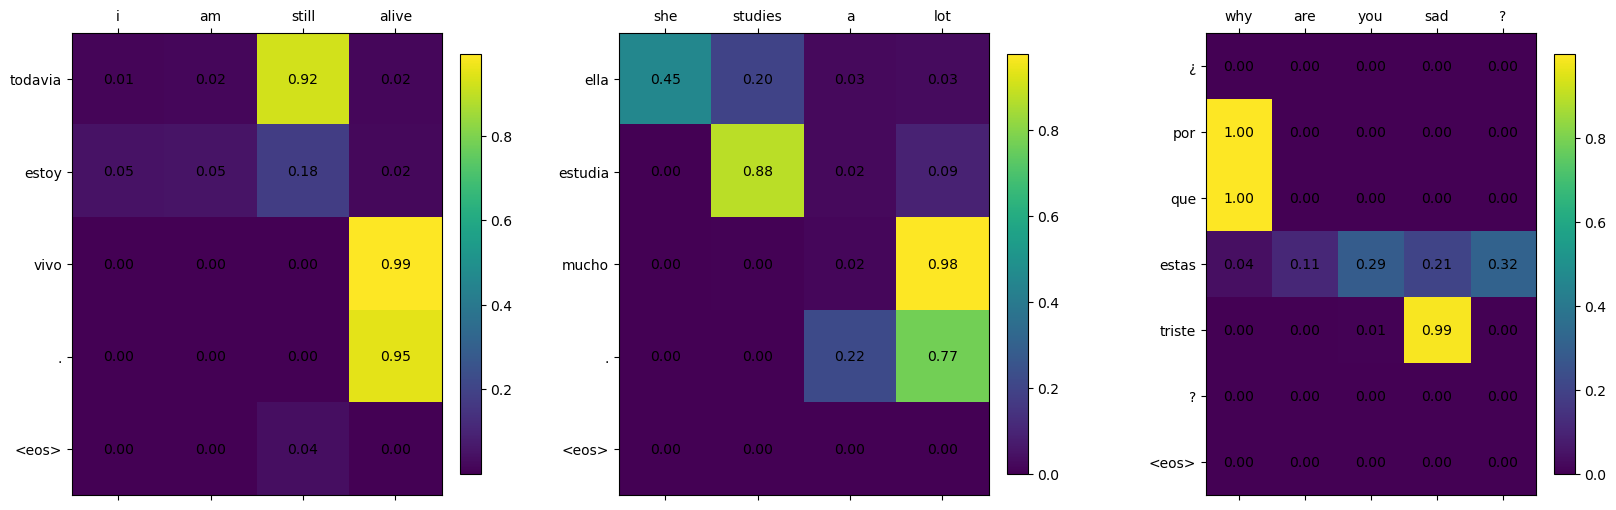

In [32]:
plot_attention(test_sents)